# 🐾 Animal Classification — MaxViT-Base/224 (Head-Only)

**5-Fold CV · Optuna HPO · Macro F1 · Frozen Backbone**

**Run `00_shared_splits` first.**

- Valid pretrained `timm` model: `maxvit_base_tf_224.in1k`.
- Input size 224 × 224 to match this checkpoint's fixed pretrained input configuration.
- Backbone remains frozen; only the classification head trains.
- Dual average + max pooling over the spatial feature map.
- Five-fold CV, Optuna hyperparameter search, macro-F1 checkpointing, TTA, and submission artifacts.


## 0. Config

In [1]:
SPLIT_SEED   = 42
N_FOLDS      = 5
SPLITS_DIR   = "/kaggle/input/notebooks/freegpu1234576/aog-data-split/splits"

CFG = dict(
    model_name    = "maxvit_base_tf_224.in1k",
    img_size      = 224,
    batch_size    = 32,
    num_workers   = 2,
    warmup_epochs = 0,            # no warmup — head-only from epoch 1
    total_epochs  = 25,
    patience      = 7,
    lr            = 1e-3,         # high lr fine — backbone frozen
    wd            = 1e-4,
    lr_decay      = 1.0,          # unused — head-only
    scheduler     = "cosine",
    dropout       = 0.3,
    hidden_dim    = 512,
    mixup_alpha   = 0.0,          # no mixup for head-only (simpler)
    label_smooth  = 0.1,
    grad_clip     = 1.0,
    n_trials      = 20,
    output_dir    = "/kaggle/working",
)
OPTUNA_WARMUP_EP  = 0
OPTUNA_FT_EP      = 4
OPTUNA_BS_CHOICES = [16, 32, 64]


## 1. Imports & Setup

In [2]:
%pip -q install -U timm

import os, sys, json, logging, zipfile, random, time
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import f1_score

import optuna
from optuna.samplers import TPESampler
optuna.logging.set_verbosity(optuna.logging.WARNING)

def seed_everything(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(SPLIT_SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = device.type == "cuda"
print("Device:", device)

OUT     = Path(CFG["output_dir"])
WEIGHTS = OUT / "weights"; LOGS = OUT / "logs"; SUBS = OUT / "submissions"
for d in [WEIGHTS, LOGS, SUBS]: d.mkdir(parents=True, exist_ok=True)

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(message)s",
    handlers=[
        logging.FileHandler(LOGS / "training.log"),
        logging.StreamHandler(sys.stdout),
    ]
)
log = logging.getLogger(__name__)
log.info(f"Config: {CFG}")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 31.1 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.
Device: cuda
2026-10-10 08:26:42,801 | INFO | Config: {'model_name': 'maxvit_base_tf_224.in1k', 'img_size': 224, 'batch_size': 32, 'num_workers': 2, 'warmup_epochs': 0, 'total_epochs': 25, 'patience': 7, 'lr': 0.001, 'wd': 0.0001, 'lr_decay': 1.0, 'scheduler': 'cosine', 'dropout': 0.3, 'hidden_dim': 512, 'mixup_alpha': 0.0, 'label_smooth': 0.1, 'grad_clip': 1.0, 'n_trials': 20, 'output_dir': '/kaggle/working'}


## 2. Load Data & Splits

In [3]:
def find_file(name):
    for root, _, files in os.walk("/kaggle/input"):
        if name in files: return os.path.join(root, name)
    raise FileNotFoundError(name)

train_csv    = find_file("train.csv")
sample_csv   = find_file("sample_submission.csv")
base_dir     = os.path.dirname(train_csv)
TRAIN_DIR    = os.path.join(base_dir, "train_images")
TEST_DIR     = os.path.join(base_dir, "test_images")

full_df       = pd.read_csv(train_csv)
submission_df = pd.read_csv(sample_csv)

classes      = sorted(full_df["animal_class"].unique())
NUM_CLASSES  = len(classes)
class_to_idx = {c: i for i, c in enumerate(classes)}
idx_to_class = {i: c for c, i in class_to_idx.items()}
full_df["label"] = full_df["animal_class"].map(class_to_idx)

holdout_data = np.load(f"{SPLITS_DIR}/holdout.npz")
holdout_idx  = holdout_data["holdout_idx"]
trainval_idx = holdout_data["trainval_idx"]

log.info(f"Total:{len(full_df)} TrainVal:{len(trainval_idx)} Holdout:{len(holdout_idx)} Classes:{NUM_CLASSES}")
print(full_df.head(3))


2026-10-10 08:26:42,896 | INFO | Total:3087 TrainVal:2623 Holdout:464 Classes:72
                               image_id animal_class  label
0          000dc07b2b676f5d0ec0acf9.png     reindeer     51
1  0063d33c0996495e9337062ad3f13319.png     antelope      0
2          007227c159bdba58d63406ca.png        sheep     57


## 3. Augmentation & Datasets

In [4]:
# ── Core idea: colour is NOT a class signal in this competition ──
# Segmentation images have arbitrary colours per instance.
# Strategy: destroy colour information aggressively, force the model
# to learn SHAPE, SILHOUETTE and STRUCTURAL cues only.

MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]
SZ   = CFG["img_size"]

# Strong colour destruction + shape-preserving spatial augmentation
train_tf = transforms.Compose([
    transforms.Resize((int(SZ * 1.15), int(SZ * 1.15))),   # slightly oversized then crop
    transforms.RandomCrop((SZ, SZ)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.15),
    transforms.RandomRotation(degrees=30),
    # Colour destruction — hue=0.5 is max, full saturation/brightness swing
    transforms.ColorJitter(brightness=0.8, contrast=0.8, saturation=1.0, hue=0.5),
    # 30 % chance of full grayscale — forces shape-only features
    transforms.RandomGrayscale(p=0.3),
    # Simulate different segmentation renders
    transforms.RandomPosterize(bits=4, p=0.2),
    transforms.RandomSolarize(threshold=128, p=0.1),
    transforms.RandomAffine(
        degrees=0, translate=(0.15, 0.15),
        scale=(0.8, 1.2), shear=10,
    ),
    transforms.RandomPerspective(distortion_scale=0.3, p=0.3),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
    # Random erasing: occludes body parts, prevents relying on specific regions
    transforms.RandomErasing(p=0.3, scale=(0.02, 0.2), ratio=(0.3, 3.3)),
])

val_tf = transforms.Compose([
    transforms.Resize((SZ, SZ)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# TTA transform — used at inference only (slight flips + colour jitter)
def tta_transforms(img_size):
    return [
        transforms.Compose([transforms.Resize((img_size, img_size)),
                             transforms.ToTensor(), transforms.Normalize(MEAN, STD)]),
        transforms.Compose([transforms.Resize((img_size, img_size)),
                             transforms.RandomHorizontalFlip(p=1.0),
                             transforms.ToTensor(), transforms.Normalize(MEAN, STD)]),
        transforms.Compose([transforms.Resize((int(img_size*1.1), int(img_size*1.1))),
                             transforms.CenterCrop(img_size),
                             transforms.ToTensor(), transforms.Normalize(MEAN, STD)]),
    ]
TTA_TFS = tta_transforms(SZ)


class AnimalDS(Dataset):
    def __init__(self, df, image_dir, tf=None):
        self.df = df.reset_index(drop=True)
        self.image_dir = image_dir; self.tf = tf
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(os.path.join(self.image_dir, row["image_id"])).convert("RGB")
        if self.tf: img = self.tf(img)
        return img, int(row["label"])

class TestDS(Dataset):
    def __init__(self, df, image_dir, tf):
        self.df = df.reset_index(drop=True)
        self.image_dir = image_dir; self.tf = tf
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        iid = self.df.iloc[i]["image_id"]
        return self.tf(Image.open(os.path.join(self.image_dir, iid)).convert("RGB")), iid

test_ds   = TestDS(submission_df, TEST_DIR, val_tf)
te_loader = DataLoader(test_ds, batch_size=CFG["batch_size"],
                       shuffle=False, num_workers=CFG["num_workers"], pin_memory=True)
print("Datasets & TTA transforms ready.")


Datasets & TTA transforms ready.


## 4. Training Helpers

In [5]:
# ── Mixup ─────────────────────────────────────────────────────────
def mixup_data(x, y, alpha=0.4):
    if alpha <= 0: return x, y, y, 1.0
    lam = np.random.beta(alpha, alpha)
    idx = torch.randperm(x.size(0), device=x.device)
    return x * lam + x[idx] * (1 - lam), y, y[idx], lam

def mixup_criterion(criterion, pred, ya, yb, lam):
    return lam * criterion(pred, ya) + (1 - lam) * criterion(pred, yb)


def make_loaders(tr_df, val_df, bs=None):
    bs = bs or CFG["batch_size"]
    return (
        DataLoader(AnimalDS(tr_df, TRAIN_DIR, train_tf),
                   batch_size=bs, shuffle=True,
                   num_workers=CFG["num_workers"], pin_memory=True, drop_last=True),
        DataLoader(AnimalDS(val_df, TRAIN_DIR, val_tf),
                   batch_size=bs, shuffle=False,
                   num_workers=CFG["num_workers"], pin_memory=True),
    )


def train_epoch(model, loader, optimizer, criterion, scaler, use_mixup=True):
    model.train()
    tl, correct, total = 0., 0, 0
    preds_all, labels_all = [], []
    n_steps = len(loader)

    for step, (imgs, labels) in enumerate(loader, 1):
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()

        # Mixup (disabled during warmup via use_mixup flag)
        if use_mixup and CFG.get("mixup_alpha", 0) > 0:
            imgs, ya, yb, lam = mixup_data(imgs, labels, CFG["mixup_alpha"])
            with torch.cuda.amp.autocast(enabled=AMP):
                out  = model(imgs)
                loss = mixup_criterion(criterion, out, ya, yb, lam)
        else:
            with torch.cuda.amp.autocast(enabled=AMP):
                out  = model(imgs)
                loss = criterion(out, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), CFG.get("grad_clip", 1.0))
        scaler.step(optimizer); scaler.update()

        tl += loss.item() * imgs.size(0)
        preds = out.argmax(1)
        correct += (preds == labels).sum().item()
        total   += imgs.size(0)
        preds_all.extend(preds.cpu().numpy())
        labels_all.extend(labels.cpu().numpy())

        if step % 20 == 0:
            run_f1   = f1_score(labels_all, preds_all, average="macro", zero_division=0)
            run_acc  = correct / total
            run_loss = tl / total
            log.info(
                f"    step {step:04d}/{n_steps} | "
                f"loss={run_loss:.4f}  acc={run_acc:.4f}  macro_f1={run_f1:.4f}"
            )

    return tl/total, correct/total, f1_score(labels_all, preds_all, average="macro", zero_division=0)


@torch.no_grad()
def val_epoch(model, loader, criterion):
    model.eval()
    tl, correct, total = 0., 0, 0
    preds_all, labels_all, probs_all = [], [], []
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        with torch.cuda.amp.autocast(enabled=AMP):
            out  = model(imgs)
            loss = criterion(out, labels)
        tl += loss.item() * imgs.size(0)
        preds = out.argmax(1)
        correct += (preds == labels).sum().item()
        total   += imgs.size(0)
        preds_all.extend(preds.cpu().numpy())
        labels_all.extend(labels.cpu().numpy())
        probs_all.append(F.softmax(out, dim=1).cpu().numpy())
    val_f1 = f1_score(labels_all, preds_all, average="macro", zero_division=0)
    return tl/total, correct/total, val_f1, np.concatenate(probs_all)


@torch.no_grad()
def predict_tta(model, df, image_dir):
    """Test-time augmentation: average softmax over TTA_TFS transforms."""
    model.eval()
    all_probs = []
    for tf in TTA_TFS:
        ds     = TestDS(df, image_dir, tf)
        loader = DataLoader(ds, batch_size=CFG["batch_size"], shuffle=False,
                            num_workers=CFG["num_workers"], pin_memory=True)
        probs  = []
        for imgs, _ in loader:
            with torch.cuda.amp.autocast(enabled=AMP):
                probs.append(F.softmax(model(imgs.to(device)), dim=1).cpu().numpy())
        all_probs.append(np.concatenate(probs))
    return np.mean(all_probs, axis=0)   # (N, C) averaged over TTA views


def make_scheduler(optimizer, name, epochs):
    if name == "cosine":
        return torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-8)
    elif name == "cosine_wr":
        return torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=max(1,epochs//3), T_mult=2)
    else:
        return torch.optim.lr_scheduler.StepLR(optimizer, step_size=max(1,epochs//3), gamma=0.3)


print("Helpers ready  (mixup + TTA enabled).")


Helpers ready  (mixup + TTA enabled).


## 5. Plotting Helpers

In [6]:
def plot_fold(fold, h):
    epochs = range(1, len(h["tr_loss"])+1)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    fig.suptitle(f"{CFG['model_name']}  |  Fold {fold}  |  best val F1={max(h['val_f1']):.4f}", fontsize=12)
    for ax, (tk, vk, title, yl) in zip(axes, [
        ("tr_loss","val_loss","Loss","Loss"),
        ("tr_f1",  "val_f1",  "Macro F1","F1"),
        ("tr_acc", "val_acc", "Accuracy","Acc"),
    ]):
        ax.plot(epochs, h[tk], label="train", marker="o", ms=3)
        ax.plot(epochs, h[vk], label="val",   marker="o", ms=3)
        if "wu_end" in h:
            ax.axvline(x=h["wu_end"]+.5, color="gray", ls="--", alpha=.5, label="unfreeze")
        ax.set_title(title); ax.set_xlabel("Epoch"); ax.set_ylabel(yl)
        ax.legend(); ax.grid(alpha=.3)
    plt.tight_layout(); plt.show(); plt.close()

def plot_optuna(study):
    try:
        fig, axes = plt.subplots(1, 2, figsize=(14, 4))
        trials = [t for t in study.trials if t.value is not None]
        vals   = [t.value for t in trials]
        best_so_far = [max(vals[:i+1]) for i in range(len(vals))]
        axes[0].plot(vals, marker="o", ms=4, alpha=0.6, label="trial F1")
        axes[0].plot(best_so_far, color="red", lw=2, label="best so far")
        axes[0].set_title("Optuna — optimisation history")
        axes[0].set_xlabel("Trial"); axes[0].set_ylabel("Val macro F1")
        axes[0].legend(); axes[0].grid(alpha=.3)
        try:
            imp = optuna.importance.get_param_importances(study)
            axes[1].barh(list(imp.keys()), list(imp.values()))
            axes[1].set_title("Param importances"); axes[1].set_xlabel("Importance")
            axes[1].invert_yaxis(); axes[1].grid(alpha=.3)
        except Exception:
            axes[1].text(0.5, 0.5, "importance N/A\\n(need ≥2 trials)", ha="center", va="center")
        plt.tight_layout(); plt.show(); plt.close()
    except Exception as e:
        print(f"Optuna plot skipped: {e}")


## 6. Model — MaxViT-Base/224 (Head-Only)

In [7]:
import timm

class MaxViTBaseClassifier(nn.Module):
    """
    MaxViT-Base @ 224px — backbone PERMANENTLY FROZEN.
    Only the classification head trains.
    Dual avg+max pool over spatial feature map.
    """
    def __init__(self, dropout=0.3, hidden_dim=512):
        super().__init__()
        self.backbone = timm.create_model(
            "maxvit_base_tf_224.in1k",
            pretrained=True,
            num_classes=0,
            global_pool="",
        )
        # Freeze permanently inside __init__
        for p in self.backbone.parameters():
            p.requires_grad = False

        in_f = self.backbone.num_features   # inferred from this checkpoint (768 for this variant)
        self.head = nn.Sequential(
            nn.LayerNorm(in_f * 2),
            nn.Linear(in_f * 2, hidden_dim), nn.GELU(),
            nn.Dropout(p=dropout),
            nn.Linear(hidden_dim, NUM_CLASSES),
        )
    def forward(self, x):
        feat = self.backbone.forward_features(x)

        # Convert to NCHW only if features are actually NHWC.
        # MaxViT's output is normally NCHW: (B, C, H, W).
        if feat.ndim == 4:
            if feat.shape[1] == self.backbone.num_features:
                pass  # Already NCHW
            elif feat.shape[-1] == self.backbone.num_features:
                feat = feat.permute(0, 3, 1, 2)  # NHWC -> NCHW
            else:
                raise RuntimeError(
                    f"Unexpected MaxViT feature shape: {tuple(feat.shape)}; "
                    f"num_features={self.backbone.num_features}"
                )
        else:
            raise RuntimeError(
                f"Expected 4D spatial features, got {tuple(feat.shape)}"
            )

        avg = F.adaptive_avg_pool2d(feat, 1).flatten(1)
        mx = F.adaptive_max_pool2d(feat, 1).flatten(1)

        return self.head(torch.cat([avg, mx], dim=1))

def build_model(dropout=None, hidden_dim=None):
    return MaxViTBaseClassifier(
        dropout    = dropout    or CFG["dropout"],
        hidden_dim = hidden_dim or CFG["hidden_dim"],
    )
# Backbone is already frozen inside __init__ — these are no-ops but
# kept for compatibility with the shared training loop
def freeze_backbone(m): pass
def unfreeze_backbone(m): pass   # ← never called; warmup_epochs=0
def get_head_params(m): return list(m.head.parameters())
def build_optimizer(m, lr=None, wd=None, lr_decay=None):
    # Only head params — backbone has requires_grad=False
    lr = lr or CFG["lr"]; wd = wd or CFG["wd"]
    return torch.optim.AdamW(m.head.parameters(), lr=lr, weight_decay=wd)

# Verify backbone is truly frozen
_m = build_model().to(device)
trainable = sum(p.numel() for p in _m.parameters() if p.requires_grad)
head_only  = sum(p.numel() for p in _m.head.parameters())
assert trainable == head_only, f"Backbone leak! trainable={trainable} head={head_only}"
with torch.no_grad():
    assert _m(torch.randn(2,3,CFG["img_size"],CFG["img_size"]).to(device)).shape==(2,NUM_CLASSES)
in_f = _m.backbone.num_features
del _m; torch.cuda.empty_cache()
print(f"MaxViT-Base/224 OK  in_features={in_f}  trainable={head_only/1e3:.1f}K (head only)")


2026-10-10 08:26:47,585 | INFO | Loading pretrained weights from Hugging Face hub (timm/maxvit_base_tf_224.in1k)
2026-10-10 08:26:47,696 | INFO | HTTP Request: GET https://huggingface.co/api/agent-harnesses "HTTP/1.1 200 OK"
2026-10-10 08:26:47,740 | INFO | HTTP Request: HEAD https://huggingface.co/timm/maxvit_base_tf_224.in1k/resolve/main/model.safetensors "HTTP/1.1 302 Found"


2026-10-10 08:26:47,741 | WARNING | Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
2026-10-10 08:26:47,847 | INFO | HTTP Request: GET https://huggingface.co/api/models/timm/maxvit_base_tf_224.in1k/xet-read-token/5acb920172dae4dec544fd8e827570f91caddbc9 "HTTP/1.1 200 OK"


model.safetensors: reconstructing file:   0%|          |  0.00B /  479MB            

model.safetensors: downloading bytes:           |  0.00B            

2026-10-10 08:26:51,400 | INFO | [timm/maxvit_base_tf_224.in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.
MaxViT-Base/224 OK  in_features=768  trainable=827.0K (head only)


## 7. Optuna HPO

Runs on Fold 0 as proxy.  
Tunes: `lr`, `wd`, `dropout`, `hidden_dim`, `batch_size`, `scheduler`, `lr_decay`, `mixup_alpha`, `label_smooth`.

2026-10-10 08:26:55,438 | INFO | Optuna: 20 trials | warmup=0 | finetune=4


  0%|          | 0/20 [00:00<?, ?it/s]

2026-10-10 08:26:57,181 | INFO | Loading pretrained weights from Hugging Face hub (timm/maxvit_base_tf_224.in1k)
2026-10-10 08:26:57,286 | INFO | HTTP Request: HEAD https://huggingface.co/timm/maxvit_base_tf_224.in1k/resolve/main/model.safetensors "HTTP/1.1 302 Found"
2026-10-10 08:26:57,288 | INFO | [timm/maxvit_base_tf_224.in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


/tmp/ipykernel_22/37480987.py:18: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler    = torch.cuda.amp.GradScaler(enabled=AMP)
/tmp/ipykernel_22/4249933402.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP):


2026-10-10 08:27:15,159 | INFO |     step 0020/65 | loss=4.3044  acc=0.0109  macro_f1=0.0040


...

2026-10-10 09:35:23,661 | INFO |     step 0100/131 | loss=4.1098  acc=0.0744  macro_f1=0.0509


/tmp/ipykernel_22/4249933402.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP):


2026-10-10 09:35:29,766 | INFO |     step 0120/131 | loss=4.1102  acc=0.0766  macro_f1=0.0518


/tmp/ipykernel_22/4249933402.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP):
/tmp/ipykernel_22/4249933402.py:76: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP):


2026-10-10 09:35:43,450 | INFO | Optuna best val macro F1 = 0.2881
2026-10-10 09:35:43,452 | INFO | Best params: {'lr': 0.00014841175752807395, 'wd': 0.0010404798251088814, 'dropout': 0.13128805995093892, 'hidden_dim': 384, 'batch_size': 16, 'scheduler': 'cosine', 'lr_decay': 0.5797424465540723, 'mixup_alpha': 0.004245429395062755, 'label_smooth': 0.10001515560019977}
2026-10-10 09:35:43,474 | INFO | CFG patched with best params: {'model_name': 'maxvit_base_tf_224.in1k', 'img_size': 224, 'batch_size': 16, 'num_workers': 2, 'warmup_epochs': 0, 'total_epochs': 25, 'patience': 7, 'lr': 0.00014841175752807395, 'wd': 0.0010404798251088814, 'lr_decay': 0.5797424465540723, 'scheduler': 'cosine', 'dropout': 0.13128805995093892, 'hidden_dim': 384, 'mixup_alpha': 0.004245429395062755, 'label_smooth': 0.10001515560019977, 'grad_clip': 1.0, 'n_trials': 20, 'output_dir': '/kaggle/working'}


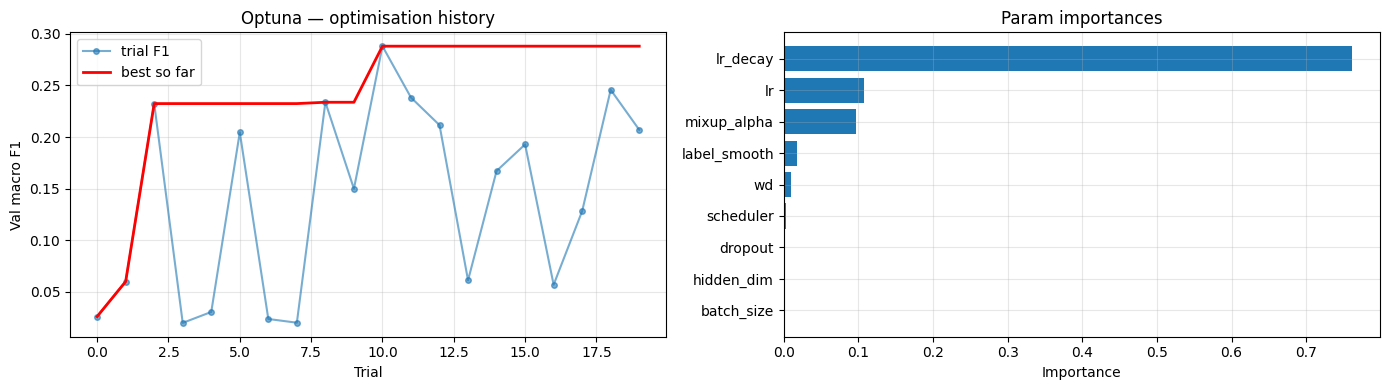

Best params: {'lr': 0.00014841175752807395, 'wd': 0.0010404798251088814, 'dropout': 0.13128805995093892, 'hidden_dim': 384, 'batch_size': 16, 'scheduler': 'cosine', 'lr_decay': 0.5797424465540723, 'mixup_alpha': 0.004245429395062755, 'label_smooth': 0.10001515560019977}


In [8]:
_opt_data  = np.load(f"{SPLITS_DIR}/fold_0.npz")
_opt_tr_df = full_df.iloc[_opt_data["train_idx"]]
_opt_val_df= full_df.iloc[_opt_data["val_idx"]]

def _optuna_objective(trial):
    lr          = trial.suggest_float("lr",          1e-5, 3e-4, log=True)
    wd          = trial.suggest_float("wd",          1e-5, 1e-2, log=True)
    dropout     = trial.suggest_float("dropout",     0.1,  0.4)
    hidden_dim  = trial.suggest_categorical("hidden_dim",  [384, 512, 768])
    bs          = trial.suggest_categorical("batch_size",  OPTUNA_BS_CHOICES)
    sched       = trial.suggest_categorical("scheduler",   ["cosine", "cosine_wr"])
    lr_decay    = trial.suggest_float("lr_decay",    0.55, 0.85)
    mixup_alpha = trial.suggest_float("mixup_alpha", 0.0,  0.5)
    label_smooth= trial.suggest_float("label_smooth",0.05, 0.2)

    model     = build_model(dropout=dropout, hidden_dim=hidden_dim).to(device)
    criterion = nn.CrossEntropyLoss(label_smoothing=label_smooth)
    scaler    = torch.cuda.amp.GradScaler(enabled=AMP)
    tr_loader, val_loader = make_loaders(_opt_tr_df, _opt_val_df, bs=bs)

    # Warmup — frozen, no mixup
    freeze_backbone(model)
    opt_wu = torch.optim.AdamW(get_head_params(model), lr=lr*10, weight_decay=wd)
    sch_wu = torch.optim.lr_scheduler.CosineAnnealingLR(opt_wu, T_max=OPTUNA_WARMUP_EP, eta_min=lr)
    for _ in range(OPTUNA_WARMUP_EP):
        train_epoch(model, tr_loader, opt_wu, criterion, scaler, use_mixup=False)
        sch_wu.step()

    # Finetune — unfrozen, with mixup
    unfreeze_backbone(model)
    _tmp_alpha = CFG.get("mixup_alpha", 0)
    CFG["mixup_alpha"] = mixup_alpha
    opt_ft = build_optimizer(model, lr=lr, wd=wd, lr_decay=lr_decay)
    sch_ft = make_scheduler(opt_ft, sched, OPTUNA_FT_EP)
    for ep in range(OPTUNA_FT_EP):
        train_epoch(model, tr_loader, opt_ft, criterion, scaler, use_mixup=True)
        sch_ft.step()
        _, _, vf1, _ = val_epoch(model, val_loader, criterion)
        trial.report(vf1, ep)
        if trial.should_prune():
            CFG["mixup_alpha"] = _tmp_alpha
            del model; torch.cuda.empty_cache()
            raise optuna.exceptions.TrialPruned()
    CFG["mixup_alpha"] = _tmp_alpha

    _, _, vf1, _ = val_epoch(model, val_loader, criterion)
    del model; torch.cuda.empty_cache()
    return vf1

log.info(f"Optuna: {CFG['n_trials']} trials | warmup={OPTUNA_WARMUP_EP} | finetune={OPTUNA_FT_EP}")
study = optuna.create_study(
    direction="maximize",
    sampler=TPESampler(seed=SPLIT_SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2),
)
study.optimize(_optuna_objective, n_trials=CFG["n_trials"], show_progress_bar=True)

BEST = study.best_params
log.info(f"Optuna best val macro F1 = {study.best_value:.4f}")
log.info(f"Best params: {BEST}")

pd.DataFrame([
    {"trial": t.number, "value": t.value, **t.params}
    for t in study.trials if t.value is not None
]).to_csv(LOGS / "optuna_trials.csv", index=False)

CFG.update({
    "lr":           BEST["lr"],
    "wd":           BEST["wd"],
    "dropout":      BEST["dropout"],
    "hidden_dim":   BEST["hidden_dim"],
    "batch_size":   BEST["batch_size"],
    "scheduler":    BEST["scheduler"],
    "lr_decay":     BEST["lr_decay"],
    "mixup_alpha":  BEST["mixup_alpha"],
    "label_smooth": BEST["label_smooth"],
})
log.info(f"CFG patched with best params: {CFG}")
plot_optuna(study)
print(f"Best params: {BEST}")


## 8. 5-Fold Training Loop

2026-10-10 09:35:44,632 | INFO | ========================================================================
2026-10-10 09:35:44,633 | INFO | FOLD 1/5  |  lr=1.48e-04  wd=1.04e-03  bs=16  sched=cosine  lr_decay=0.58  mixup=0.00
2026-10-10 09:35:44,634 | INFO | ========================================================================
2026-10-10 09:35:46,412 | INFO | Loading pretrained weights from Hugging Face hub (timm/maxvit_base_tf_224.in1k)
2026-10-10 09:35:46,506 | INFO | HTTP Request: HEAD https://huggingface.co/timm/maxvit_base_tf_224.in1k/resolve/main/model.safetensors "HTTP/1.1 302 Found"
2026-10-10 09:35:46,508 | INFO | [timm/maxvit_base_tf_224.in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.
2026-10-10 09:35:46,827 | INFO |   Phase 1 — FROZEN | warmup_epochs=0 | head lr=1.48e-03
2026-10-10 09:35:46,828 | INFO |   Phase 2 — UNFROZEN | lr_decay=0.58 | sched=cosine | mixup_alpha=0.00


/tmp/ipykernel_22/953221127.py:20: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler    = torch.cuda.amp.GradScaler(enabled=AMP)
/tmp/ipykernel_22/4249933402.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP):


2026-10-10 09:35:54,248 | INFO |     step 0020/131 | loss=4.3266  acc=0.0094  macro_f1=0.0019


/tmp/ipykernel_22/4249933402.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP):


2026-10-10 09:35:59,867 | INFO |     step 0040/131 | loss=4.3010  acc=0.0125  macro_f1=0.0048


...

2026-10-10 09:57:07,426 | INFO |     step 0100/131 | loss=3.0650  acc=0.2006  macro_f1=0.1849


/tmp/ipykernel_22/4249933402.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP):


2026-10-10 09:57:13,283 | INFO |     step 0120/131 | loss=3.0595  acc=0.2016  macro_f1=0.1845


/tmp/ipykernel_22/4249933402.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP):
/tmp/ipykernel_22/4249933402.py:76: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP):


2026-10-10 09:57:26,732 | INFO | [finetune] Fold 1 Ep 025/25 | TRAIN → loss=3.0560  acc=0.1927  macro_f1=0.1772 | VAL   → loss=2.3832  acc=0.5638  macro_f1=0.5095 | 51s | patience 3/7
  [finetune] ep=025/25  tr_loss=3.0560  tr_f1=0.1772  tr_acc=0.1927  |  val_loss=2.3832  val_f1=0.5095  val_acc=0.5638  [51s] patience 3/7
2026-10-10 09:57:26,733 | INFO | ────────────────────────────────────────────────────────────────────────
2026-10-10 09:57:26,733 | INFO | Fold 1 DONE | best val macro F1 = 0.5189 | epochs run = 25
2026-10-10 09:57:26,734 | INFO | ────────────────────────────────────────────────────────────────────────

  ✓ Fold 1 best val macro F1 = 0.5189



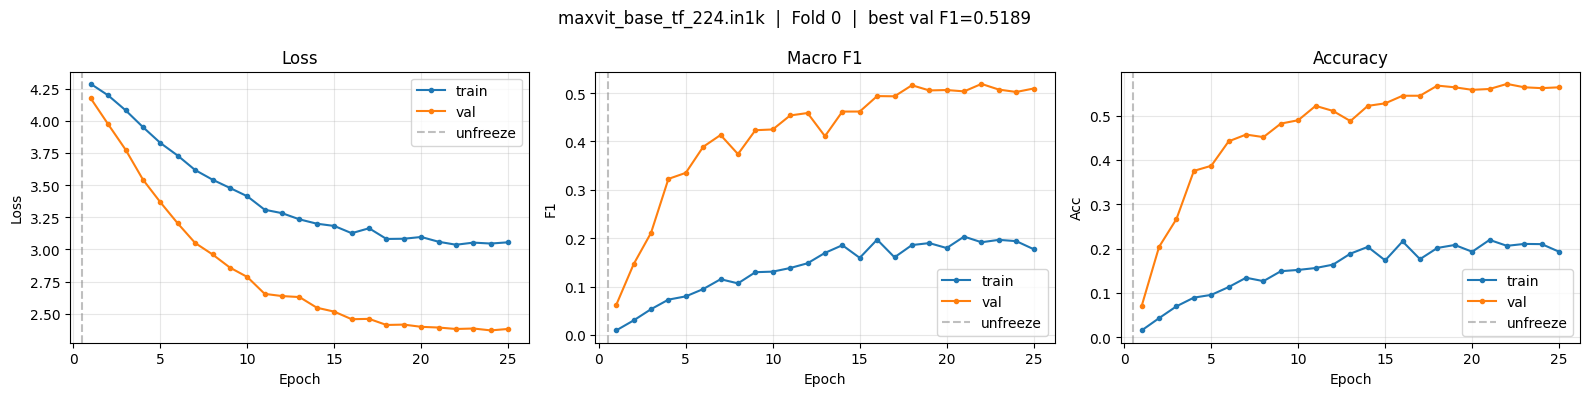

2026-10-10 09:57:27,186 | INFO |   Running TTA inference for fold 1...


/tmp/ipykernel_22/4249933402.py:101: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP):


2026-10-10 09:58:27,127 | INFO | ========================================================================
2026-10-10 09:58:27,129 | INFO | FOLD 2/5  |  lr=1.48e-04  wd=1.04e-03  bs=16  sched=cosine  lr_decay=0.58  mixup=0.00
2026-10-10 09:58:27,130 | INFO | ========================================================================
2026-10-10 09:58:28,825 | INFO | Loading pretrained weights from Hugging Face hub (timm/maxvit_base_tf_224.in1k)
2026-10-10 09:58:28,925 | INFO | HTTP Request: HEAD https://huggingface.co/timm/maxvit_base_tf_224.in1k/resolve/main/model.safetensors "HTTP/1.1 302 Found"
2026-10-10 09:58:28,927 | INFO | [timm/maxvit_base_tf_224.in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.
2026-10-10 09:58:29,232 | INFO |   Phase 1 — FROZEN | warmup_epochs=0 | head lr=1.48e-03
2026-10-10 09:58:29,233 | INFO |   Phase 2 — UNFROZEN | lr_decay=0.58 | sched=cosine | mixup_alpha=0.00


/tmp/ipykernel_22/953221127.py:20: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler    = torch.cuda.amp.GradScaler(enabled=AMP)
/tmp/ipykernel_22/4249933402.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP):


2026-10-10 09:58:36,113 | INFO |     step 0020/131 | loss=4.3037  acc=0.0219  macro_f1=0.0061


...

2026-10-10 10:19:06,246 | INFO |     step 0100/131 | loss=3.0529  acc=0.1994  macro_f1=0.1835


/tmp/ipykernel_22/4249933402.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP):


2026-10-10 10:19:12,136 | INFO |     step 0120/131 | loss=3.0741  acc=0.1802  macro_f1=0.1667


/tmp/ipykernel_22/4249933402.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP):
/tmp/ipykernel_22/4249933402.py:76: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP):


2026-10-10 10:19:24,505 | INFO | [finetune] Fold 2 Ep 025/25 | TRAIN → loss=3.0888  acc=0.1760  macro_f1=0.1636 | VAL   → loss=2.3569  acc=0.5600  macro_f1=0.4969 | 50s | patience 7/7
  [finetune] ep=025/25  tr_loss=3.0888  tr_f1=0.1636  tr_acc=0.1760  |  val_loss=2.3569  val_f1=0.4969  val_acc=0.5600  [50s] patience 7/7
2026-10-10 10:19:24,506 | INFO |   Early stop at epoch 25
2026-10-10 10:19:24,507 | INFO | ────────────────────────────────────────────────────────────────────────
2026-10-10 10:19:24,508 | INFO | Fold 2 DONE | best val macro F1 = 0.5279 | epochs run = 25
2026-10-10 10:19:24,508 | INFO | ────────────────────────────────────────────────────────────────────────

  ✓ Fold 2 best val macro F1 = 0.5279



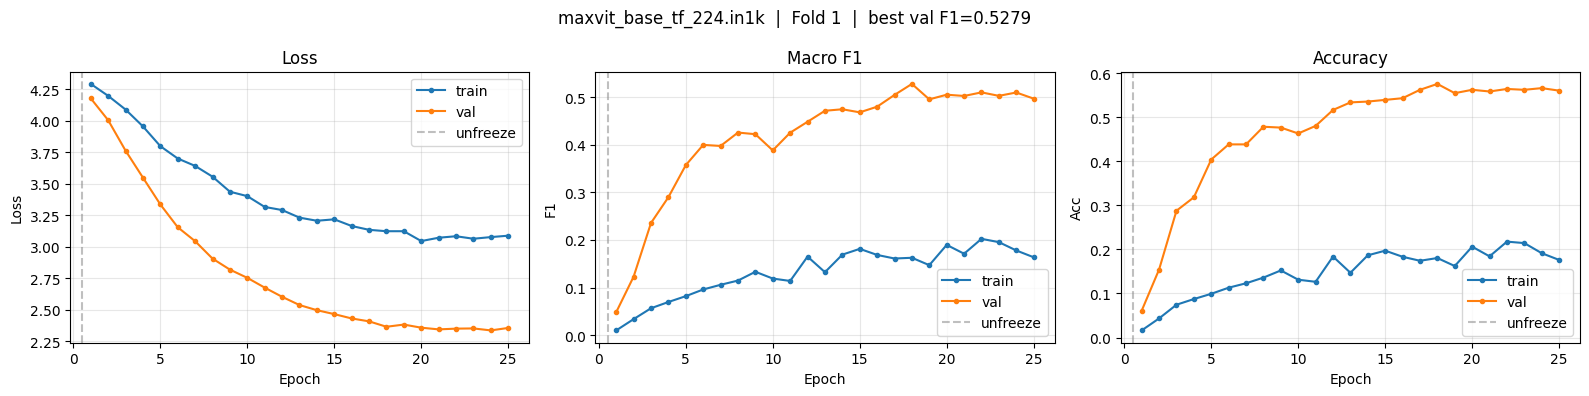

2026-10-10 10:19:24,963 | INFO |   Running TTA inference for fold 2...


/tmp/ipykernel_22/4249933402.py:101: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP):


2026-10-10 10:20:21,422 | INFO | ========================================================================
2026-10-10 10:20:21,424 | INFO | FOLD 3/5  |  lr=1.48e-04  wd=1.04e-03  bs=16  sched=cosine  lr_decay=0.58  mixup=0.00
2026-10-10 10:20:21,425 | INFO | ========================================================================
2026-10-10 10:20:23,444 | INFO | Loading pretrained weights from Hugging Face hub (timm/maxvit_base_tf_224.in1k)
2026-10-10 10:20:23,531 | INFO | HTTP Request: HEAD https://huggingface.co/timm/maxvit_base_tf_224.in1k/resolve/main/model.safetensors "HTTP/1.1 302 Found"
2026-10-10 10:20:23,533 | INFO | [timm/maxvit_base_tf_224.in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.
2026-10-10 10:20:23,846 | INFO |   Phase 1 — FROZEN | warmup_epochs=0 | head lr=1.48e-03
2026-10-10 10:20:23,847 | INFO |   Phase 2 — UNFROZEN | lr_decay=0.58 | sched=cosine | mixup_alpha=0.00


/tmp/ipykernel_22/953221127.py:20: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler    = torch.cuda.amp.GradScaler(enabled=AMP)
/tmp/ipykernel_22/4249933402.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP):


2026-10-10 10:20:32,190 | INFO |     step 0020/131 | loss=4.3211  acc=0.0219  macro_f1=0.0031


...

2026-10-10 10:41:46,734 | INFO |     step 0100/131 | loss=3.0521  acc=0.1856  macro_f1=0.1738


/tmp/ipykernel_22/4249933402.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP):


2026-10-10 10:41:53,003 | INFO |     step 0120/131 | loss=3.0270  acc=0.1995  macro_f1=0.1846


/tmp/ipykernel_22/4249933402.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP):
/tmp/ipykernel_22/4249933402.py:76: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP):


2026-10-10 10:42:05,154 | INFO | [finetune] Fold 3 Ep 025/25 | TRAIN → loss=3.0359  acc=0.1994  macro_f1=0.1855 | VAL   → loss=2.3441  acc=0.6133  macro_f1=0.5719 | 51s | ★ best
  [finetune] ep=025/25  tr_loss=3.0359  tr_f1=0.1855  tr_acc=0.1994  |  val_loss=2.3441  val_f1=0.5719  val_acc=0.6133  [51s] ★ best
2026-10-10 10:42:05,155 | INFO | ────────────────────────────────────────────────────────────────────────
2026-10-10 10:42:05,156 | INFO | Fold 3 DONE | best val macro F1 = 0.5719 | epochs run = 25
2026-10-10 10:42:05,157 | INFO | ────────────────────────────────────────────────────────────────────────

  ✓ Fold 3 best val macro F1 = 0.5719



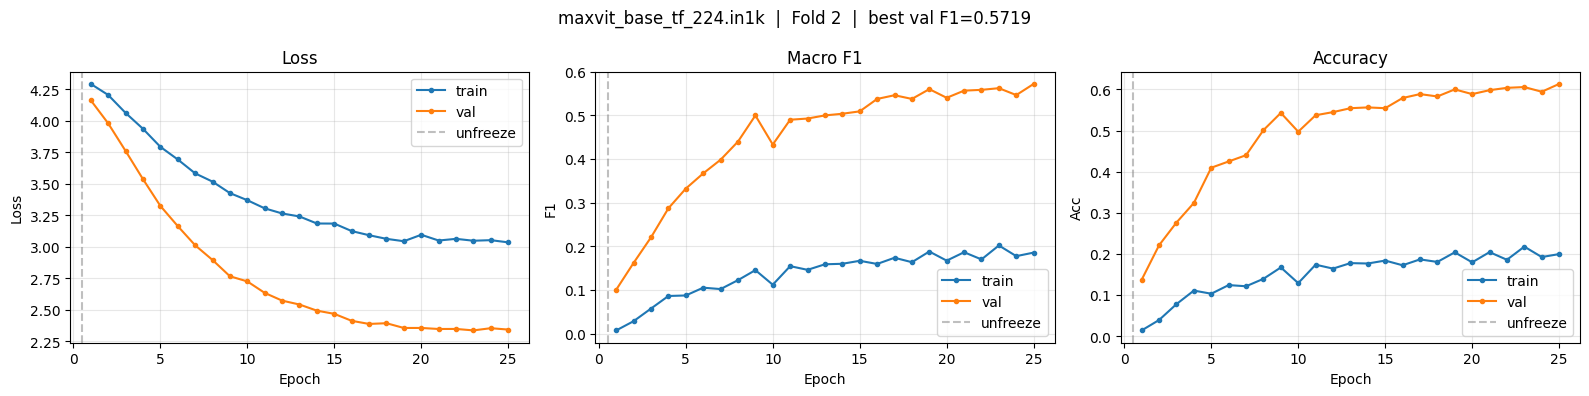

2026-10-10 10:42:05,608 | INFO |   Running TTA inference for fold 3...


/tmp/ipykernel_22/4249933402.py:101: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP):


2026-10-10 10:43:01,121 | INFO | ========================================================================
2026-10-10 10:43:01,123 | INFO | FOLD 4/5  |  lr=1.48e-04  wd=1.04e-03  bs=16  sched=cosine  lr_decay=0.58  mixup=0.00
2026-10-10 10:43:01,124 | INFO | ========================================================================
2026-10-10 10:43:02,986 | INFO | Loading pretrained weights from Hugging Face hub (timm/maxvit_base_tf_224.in1k)
2026-10-10 10:43:03,088 | INFO | HTTP Request: HEAD https://huggingface.co/timm/maxvit_base_tf_224.in1k/resolve/main/model.safetensors "HTTP/1.1 302 Found"
2026-10-10 10:43:03,090 | INFO | [timm/maxvit_base_tf_224.in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.
2026-10-10 10:43:03,422 | INFO |   Phase 1 — FROZEN | warmup_epochs=0 | head lr=1.48e-03
2026-10-10 10:43:03,423 | INFO |   Phase 2 — UNFROZEN | lr_decay=0.58 | sched=cosine | mixup_alpha=0.00


/tmp/ipykernel_22/953221127.py:20: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler    = torch.cuda.amp.GradScaler(enabled=AMP)
/tmp/ipykernel_22/4249933402.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP):


2026-10-10 10:43:10,885 | INFO |     step 0020/131 | loss=4.3454  acc=0.0187  macro_f1=0.0020


...

2026-10-10 11:05:23,296 | INFO |     step 0100/131 | loss=3.0795  acc=0.2056  macro_f1=0.1870


/tmp/ipykernel_22/4249933402.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP):


2026-10-10 11:05:29,850 | INFO |     step 0120/131 | loss=3.0710  acc=0.2047  macro_f1=0.1868


/tmp/ipykernel_22/4249933402.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP):
/tmp/ipykernel_22/4249933402.py:76: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP):


2026-10-10 11:05:41,981 | INFO | [finetune] Fold 4 Ep 025/25 | TRAIN → loss=3.0767  acc=0.2047  macro_f1=0.1879 | VAL   → loss=2.3589  acc=0.5821  macro_f1=0.5250 | 50s | patience 1/7
  [finetune] ep=025/25  tr_loss=3.0767  tr_f1=0.1879  tr_acc=0.2047  |  val_loss=2.3589  val_f1=0.5250  val_acc=0.5821  [50s] patience 1/7
2026-10-10 11:05:41,982 | INFO | ────────────────────────────────────────────────────────────────────────
2026-10-10 11:05:41,983 | INFO | Fold 4 DONE | best val macro F1 = 0.5330 | epochs run = 25
2026-10-10 11:05:41,983 | INFO | ────────────────────────────────────────────────────────────────────────

  ✓ Fold 4 best val macro F1 = 0.5330



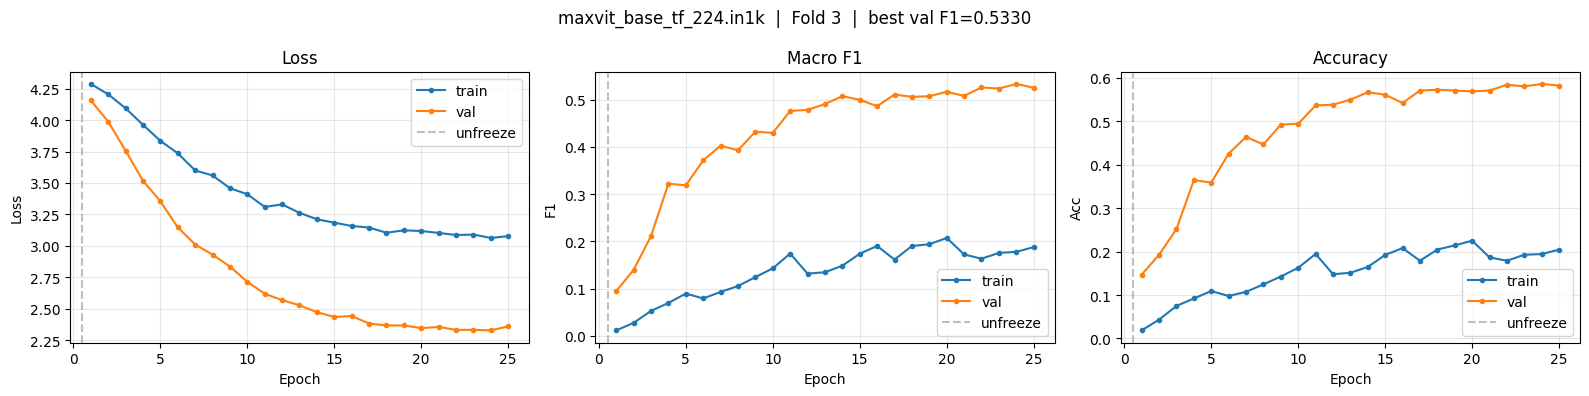

2026-10-10 11:05:42,444 | INFO |   Running TTA inference for fold 4...


/tmp/ipykernel_22/4249933402.py:101: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP):


2026-10-10 11:06:36,171 | INFO | ========================================================================
2026-10-10 11:06:36,174 | INFO | FOLD 5/5  |  lr=1.48e-04  wd=1.04e-03  bs=16  sched=cosine  lr_decay=0.58  mixup=0.00
2026-10-10 11:06:36,175 | INFO | ========================================================================
2026-10-10 11:06:37,916 | INFO | Loading pretrained weights from Hugging Face hub (timm/maxvit_base_tf_224.in1k)
2026-10-10 11:06:38,004 | INFO | HTTP Request: HEAD https://huggingface.co/timm/maxvit_base_tf_224.in1k/resolve/main/model.safetensors "HTTP/1.1 302 Found"
2026-10-10 11:06:38,006 | INFO | [timm/maxvit_base_tf_224.in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.
2026-10-10 11:06:38,314 | INFO |   Phase 1 — FROZEN | warmup_epochs=0 | head lr=1.48e-03
2026-10-10 11:06:38,315 | INFO |   Phase 2 — UNFROZEN | lr_decay=0.58 | sched=cosine | mixup_alpha=0.00


/tmp/ipykernel_22/953221127.py:20: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler    = torch.cuda.amp.GradScaler(enabled=AMP)
/tmp/ipykernel_22/4249933402.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP):


2026-10-10 11:06:45,000 | INFO |     step 0020/131 | loss=4.3337  acc=0.0156  macro_f1=0.0016


...

2026-10-10 11:27:43,410 | INFO |     step 0100/131 | loss=3.0706  acc=0.1919  macro_f1=0.1728


/tmp/ipykernel_22/4249933402.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP):


2026-10-10 11:27:49,967 | INFO |     step 0120/131 | loss=3.0718  acc=0.1948  macro_f1=0.1760


/tmp/ipykernel_22/4249933402.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP):
/tmp/ipykernel_22/4249933402.py:76: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP):


2026-10-10 11:28:02,151 | INFO | [finetune] Fold 5 Ep 025/25 | TRAIN → loss=3.0887  acc=0.1942  macro_f1=0.1746 | VAL   → loss=2.3585  acc=0.5992  macro_f1=0.5429 | 50s | patience 6/7
  [finetune] ep=025/25  tr_loss=3.0887  tr_f1=0.1746  tr_acc=0.1942  |  val_loss=2.3585  val_f1=0.5429  val_acc=0.5992  [50s] patience 6/7
2026-10-10 11:28:02,153 | INFO | ────────────────────────────────────────────────────────────────────────
2026-10-10 11:28:02,154 | INFO | Fold 5 DONE | best val macro F1 = 0.5498 | epochs run = 25
2026-10-10 11:28:02,155 | INFO | ────────────────────────────────────────────────────────────────────────

  ✓ Fold 5 best val macro F1 = 0.5498



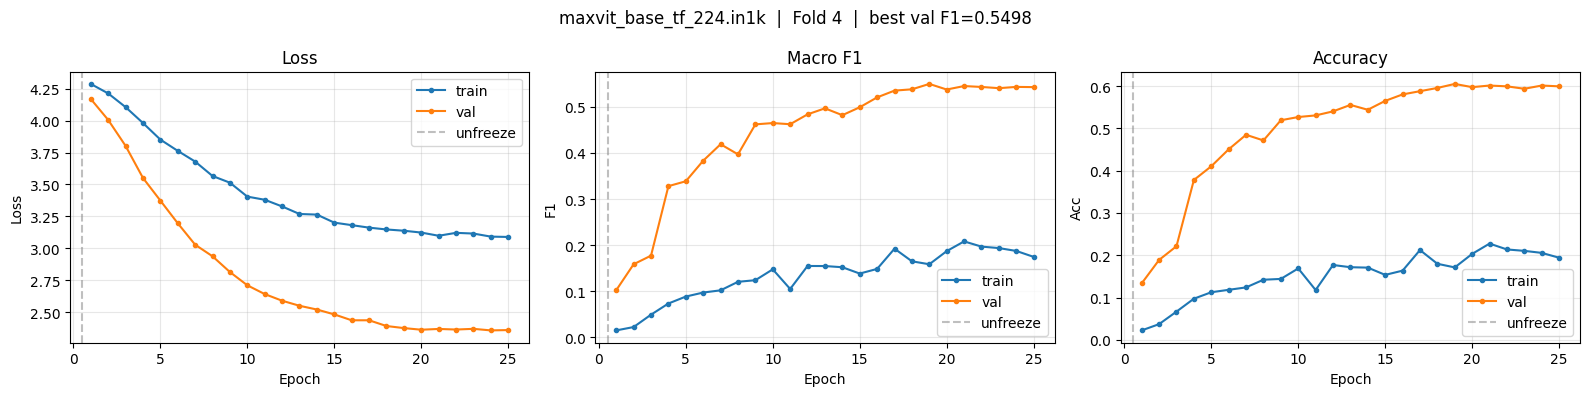

2026-10-10 11:28:02,642 | INFO |   Running TTA inference for fold 5...


/tmp/ipykernel_22/4249933402.py:101: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=AMP):


2026-10-10 11:28:56,572 | INFO | ========================================================================
2026-10-10 11:28:56,574 | INFO | ALL FOLDS DONE
2026-10-10 11:28:56,575 | INFO |   Per-fold val macro F1 : [0.5189, 0.5279, 0.5719, 0.533, 0.5498]
2026-10-10 11:28:56,576 | INFO |   Mean CV macro F1      : 0.5403
2026-10-10 11:28:56,577 | INFO |   Std                   : 0.0187
2026-10-10 11:28:56,579 | INFO | ========================================================================

CV macro F1 : 0.5403 ± 0.0187
Per-fold     : [0.5189, 0.5279, 0.5719, 0.533, 0.5498]


In [9]:
oof_probs  = np.zeros((len(full_df), NUM_CLASSES))
test_probs = np.zeros((len(submission_df), NUM_CLASSES))
fold_scores = []

for fold in range(N_FOLDS):
    log.info(f"{'='*72}")
    log.info(
        f"FOLD {fold+1}/{N_FOLDS}  |  lr={CFG['lr']:.2e}  wd={CFG['wd']:.2e}  "
        f"bs={CFG['batch_size']}  sched={CFG['scheduler']}  "
        f"lr_decay={CFG['lr_decay']:.2f}  mixup={CFG['mixup_alpha']:.2f}"
    )
    log.info(f"{'='*72}")

    data = np.load(f"{SPLITS_DIR}/fold_{fold}.npz")
    tr_loader, val_loader = make_loaders(
        full_df.iloc[data["train_idx"]], full_df.iloc[data["val_idx"]])

    model     = build_model(dropout=CFG["dropout"], hidden_dim=CFG["hidden_dim"]).to(device)
    criterion = nn.CrossEntropyLoss(label_smoothing=CFG.get("label_smooth", 0.1))
    scaler    = torch.cuda.amp.GradScaler(enabled=AMP)

    best_f1 = -1.; best_wt = WEIGHTS / f"fold{fold}_best.pt"
    no_imp  = 0
    history = dict(tr_loss=[], val_loss=[], tr_f1=[], val_f1=[], tr_acc=[], val_acc=[])
    phase   = "warmup"

    # Phase 1 — frozen backbone, no mixup
    freeze_backbone(model)
    opt_wu = torch.optim.AdamW(get_head_params(model),
                                lr=CFG["lr"]*10, weight_decay=CFG["wd"])
    sch_wu = torch.optim.lr_scheduler.CosineAnnealingLR(
        opt_wu, T_max=CFG["warmup_epochs"], eta_min=CFG["lr"])
    log.info(f"  Phase 1 — FROZEN | warmup_epochs={CFG['warmup_epochs']} | head lr={CFG['lr']*10:.2e}")

    for epoch in range(1, CFG["total_epochs"]+1):

        if epoch == CFG["warmup_epochs"] + 1:
            phase = "finetune"
            unfreeze_backbone(model)
            opt_ft = build_optimizer(model, lr=CFG["lr"],
                                      wd=CFG["wd"], lr_decay=CFG["lr_decay"])
            ft_ep  = CFG["total_epochs"] - CFG["warmup_epochs"]
            sch_ft = make_scheduler(opt_ft, CFG["scheduler"], ft_ep)
            log.info(
                f"  Phase 2 — UNFROZEN | lr_decay={CFG['lr_decay']:.2f} | "
                f"sched={CFG['scheduler']} | mixup_alpha={CFG['mixup_alpha']:.2f}"
            )

        optimizer  = opt_wu if phase == "warmup" else opt_ft
        scheduler  = sch_wu if phase == "warmup" else sch_ft
        use_mixup  = (phase == "finetune")

        t0 = time.time()
        trl, tra, trf = train_epoch(model, tr_loader, optimizer, criterion, scaler, use_mixup=use_mixup)
        vll, vla, vlf, vprobs = val_epoch(model, val_loader, criterion)
        scheduler.step()
        elapsed = time.time() - t0

        history["tr_loss"].append(trl);  history["val_loss"].append(vll)
        history["tr_f1"].append(trf);    history["val_f1"].append(vlf)
        history["tr_acc"].append(tra);   history["val_acc"].append(vla)

        if vlf > best_f1:
            best_f1 = vlf
            torch.save(model.state_dict(), best_wt)
            best_vprobs = vprobs.copy(); no_imp = 0; flag = "★ best"
        else:
            no_imp += 1; flag = f"patience {no_imp}/{CFG['patience']}"

        log.info(
            f"[{phase:8s}] Fold {fold+1} Ep {epoch:03d}/{CFG['total_epochs']} | "
            f"TRAIN → loss={trl:.4f}  acc={tra:.4f}  macro_f1={trf:.4f} | "
            f"VAL   → loss={vll:.4f}  acc={vla:.4f}  macro_f1={vlf:.4f} | "
            f"{elapsed:.0f}s | {flag}"
        )
        print(
            f"  [{phase:8s}] ep={epoch:03d}/{CFG['total_epochs']}  "
            f"tr_loss={trl:.4f}  tr_f1={trf:.4f}  tr_acc={tra:.4f}  |  "
            f"val_loss={vll:.4f}  val_f1={vlf:.4f}  val_acc={vla:.4f}  "
            f"[{elapsed:.0f}s] {flag}"
        )
        if phase == "finetune" and no_imp >= CFG["patience"]:
            log.info(f"  Early stop at epoch {epoch}"); break

    history["wu_end"] = CFG["warmup_epochs"]
    log.info(f"{'─'*72}")
    log.info(f"Fold {fold+1} DONE | best val macro F1 = {best_f1:.4f} | epochs run = {len(history['tr_f1'])}")
    log.info(f"{'─'*72}")
    print(f"\n  ✓ Fold {fold+1} best val macro F1 = {best_f1:.4f}\n")

    plot_fold(fold, history)
    fold_scores.append(best_f1)
    oof_probs[data["val_idx"]] = best_vprobs

    # TTA inference for this fold
    log.info(f"  Running TTA inference for fold {fold+1}...")
    model.load_state_dict(torch.load(best_wt, map_location=device))
    test_probs += predict_tta(model, submission_df, TEST_DIR)
    del model; torch.cuda.empty_cache()

test_probs /= N_FOLDS
log.info(f"{'='*72}")
log.info(f"ALL FOLDS DONE")
log.info(f"  Per-fold val macro F1 : {[round(s,4) for s in fold_scores]}")
log.info(f"  Mean CV macro F1      : {np.mean(fold_scores):.4f}")
log.info(f"  Std                   : {np.std(fold_scores):.4f}")
log.info(f"{'='*72}")
print(f"\nCV macro F1 : {np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}")
print(f"Per-fold     : {[round(s,4) for s in fold_scores]}")


## 9. OOF Evaluation & Submission

In [10]:
oof_preds  = oof_probs[trainval_idx].argmax(1)
oof_labels = full_df.iloc[trainval_idx]["label"].values
oof_f1     = f1_score(oof_labels, oof_preds, average="macro", zero_division=0)
log.info(f"OOF macro F1 (trainval): {oof_f1:.4f}")
print(f"OOF macro F1: {oof_f1:.4f}")

cv_f1    = np.mean(fold_scores)
sub_name = f"submission_{CFG['model_name']}_{cv_f1:.4f}.csv"
sub_df   = pd.DataFrame({
    "image_id":     submission_df["image_id"],
    "animal_class": [idx_to_class[i] for i in test_probs.argmax(1)],
})
sub_df.to_csv(SUBS / sub_name, index=False)
sub_df.to_csv(OUT  / sub_name, index=False)
np.save(LOGS / "oof_probs.npy",  oof_probs)
np.save(LOGS / "test_probs.npy", test_probs)
log.info(f"Submission: {sub_name}")
print(sub_df.head())


2026-10-10 11:28:57,102 | INFO | OOF macro F1 (trainval): 0.5456
OOF macro F1: 0.5456
2026-10-10 11:28:57,113 | INFO | Submission: submission_maxvit_base_tf_224.in1k_0.5403.csv
                               image_id animal_class
0          6eab26f8b156fda90e1bc819.png    sandpiper
1  483f71af1c174ab2a0c31a836267227d.png     antelope
2  563878772a3f47ce98cf9c10039a0219.png   chimpanzee
3  9aa782974228482390c1a237408a967a.png      hamster
4  3ed553219cf049b8bd9a65c300b02fb0.png          cat


## 10. ZIP

In [11]:
zip_path = OUT / f"{CFG['model_name']}_outputs.zip"
to_zip   = [*WEIGHTS.glob("*.pt"), *LOGS.glob("*"), *SUBS.glob("*.csv")]
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for fp in to_zip:
        zf.write(fp, fp.relative_to(OUT)); print(f"  + {fp.relative_to(OUT)}")
print(f"\n📦 {zip_path.name}  ({zip_path.stat().st_size/1e6:.1f} MB)")


  + weights/fold4_best.pt
  + weights/fold0_best.pt
  + weights/fold2_best.pt
  + weights/fold3_best.pt
  + weights/fold1_best.pt
  + logs/training.log
  + logs/test_probs.npy
  + logs/optuna_trials.csv
  + logs/oof_probs.npy
  + submissions/submission_maxvit_base_tf_224.in1k_0.5403.csv

📦 maxvit_base_tf_224.in1k_outputs.zip  (2221.5 MB)
